In [ ]:
# Install project dependencies in Google Colab / Jupyter.
%pip -q install pandas openpyxl numpy scipy scikit-learn matplotlib seaborn altair nltk textblob wordcloud pillow gensim pyLDAvis networkx plotly


In [2]:
import numpy as np
import datetime as dt
import pandas as pd
import sklearn as sk
import sklearn.metrics as skm
import sklearn.cluster as skc
import sklearn.preprocessing as skp
import matplotlib.pyplot as plt
import altair as alt
import seaborn as sns

import scipy as sp
import scipy.spatial.distance as spd
import scipy.cluster.hierarchy as sph

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from pathlib import Path
# Supply your own airport.xlsx file (original scraped data or a clearly labelled demo dataset).
possible_paths = [Path('/content/airport.xlsx'), Path('airport.xlsx'), Path('data/airport.xlsx'), Path('/content/synthetic_airport_feedback_demo.xlsx'), Path('synthetic_airport_feedback_demo.xlsx')]
dataset_path = next((p for p in possible_paths if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError('Dataset not found. Upload airport.xlsx to the Colab Files panel or place it beside this notebook. The synthetic demo workbook is optional and must be identified as synthetic.')
df = pd.read_excel(dataset_path, sheet_name='Synthetic_Comments' if 'synthetic_airport_feedback_demo' in dataset_path.name else 0)
if 'Comments' not in df.columns:
    raise ValueError('Dataset must contain a Comments column.')
df.head()

In [ ]:
df['Comments'].nunique()

50

In [ ]:
# load library
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# download the set of stop words the first time
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
# Load stop words
stop_words = stopwords.words('english')

# Show stop words
stop_words[:10]

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're"]

In [ ]:
import re
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize
import plotly.express as px
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)
stemmer = PorterStemmer()
#### Now creating some functions to do text processing
# Removing hashtags and mentions
def get_hashtags(text):
    hashtags = re.findall(r'\#\w+',text.lower())
    return hashtags
def get_mentions(text):
    mentions = re.findall(r'\@\w+',text.lower())
    return mentions

# Cleaning up the text of the tweets
def remove_content(text):
    text = re.sub(r"http\S+", "", text) #remove urls
    text=re.sub(r'\S+\.com\S+','',text) #remove urls
    text=re.sub(r'\@\w+','',text) #remove mentions
    text =re.sub(r'\#\w+','',text) #remove hashtags
    return text

def process_tweet(tweet):
    """
    tweets cleaning by
    1) lowering the case of the tweet,
    2) removing unwanted symbols and replacing them with a whitespace,
    3) split sentences into words according to whitespaces and then
    4) join back with a single whitespace as separator between various words
    """
    return " ".join(re.sub("(@[A-Za-z0-9]+)|([^0-9A-Za-z \t])", " ",tweet.lower()).split())

def process_text(text, stem=False): #clean text
    text=remove_content(text)
    lemmatizer=WordNetLemmatizer()
    text = re.sub('[^A-Za-z]', ' ', text.lower()) #remove non-alphabets
    text = re.sub(r'@[A-Za-z0-9]+', '', str(text)) # remove @mentions
    text = re.sub(r'#', '',  str(text)) # remove the '#' symbol
    text = re.sub(r'RT[\s]+', '',  str(text)) # remove RT
    text = re.sub(r'https?\/\/S+', '',  str(text)) # remove the hyperlink
    text = re.sub(r'http\S+', '',  str(text)) # remove the hyperlink
    text = re.sub(r'www\S+', '',  str(text)) # remove the www
    text = re.sub(r'pic+', '',  str(text)) # remove the pic
    text = re.sub(r'com', '',  str(text)) # remove the pic
    text = re.sub(r"\bamp\b", ' ', text.lower()) #remove "amp" which is coming from the translation of &
    text = re.sub(r"\bco\b", ' ', text.lower()) #remove "co" which was one of the top words found below
    tokenized_text = word_tokenize(text) #tokenize
    #tokenized_text = [lemmatizer.lemmatize(word) for word in tokenized_text]
    clean_text = [
         word for word in tokenized_text
         if (word not in stop_words and len(word)>1)
    ]
    if stem:
        clean_text=[stemmer.stem(word) for word in clean_text]
    clean_text = [lemmatizer.lemmatize(word) for word in clean_text]
    return ' '.join(clean_text)

#functions used to remove search terms from all the tweets
#function to remove duplicates from a string - in this case the string is the keywords used to scrape the tweets
def removeDupWithoutOrder(string):
    words = string.lower().split()
    return " ".join(sorted(set(words), key=words.index)).replace('OR', '').replace('  ', ' ')

#function to search for string i.e. remove specific words (search_terms in this case)
def remove_search(text, search_terms):
    query = text.lower()
    querywords = query.split()
    resultwords  = [word for word in querywords if word.lower() not in search_terms]
    return ' '.join(resultwords)

# define function to plot frequency of bi-grams, tri-grams, single words, phrases etc
from sklearn.feature_extraction.text import CountVectorizer
def plot_topn(sentences, ngram_range=(1,3), top=20,firstword=''):
    c=CountVectorizer(ngram_range=ngram_range)
    X=c.fit_transform(sentences)
    words=pd.DataFrame(X.sum(axis=0),columns=c.get_feature_names()).T.sort_values(0,ascending=False).reset_index()
    res=words[words['index'].apply(lambda x: firstword in x)].head(top)
    pl=px.bar(res, x='index',y=0)
    pl.update_layout(yaxis_title='count',xaxis_title='Phrases')

In [ ]:
import re
re.compile('<title>(.*)</title>')

re.compile(r'<title>(.*)</title>', re.UNICODE)

In [ ]:
import re
re.compile('<title>(.*)</title>')

re.compile(r'<title>(.*)</title>', re.UNICODE)

In [ ]:
# removing useless content (hashtags, mentions)
df['Comments']=df['Comments'].apply(str)

In [ ]:
# Several functions applied here: processing the comments to remove punctuation, hashtags, mentions

df['cleaned_comments']=df['Comments'].apply(lambda x: process_tweet(x))

In [ ]:
df

,Comments,cleaned_comments
0,This is a modern airport. The facility is inde...,this is a modern airport the facility is indee...
1,Impressive security measures to reach the airp...,impressive security measures to reach the airp...
2,KIA is a very organised Airport despite it hav...,kia is a very organised airport despite it hav...
3,The Kigali International Airport is simply ave...,the kigali international airport is simply ave...
4,Small but clean Airport. Good service and more...,small but clean airport good service and more ...
5,"10th October, 2023\nKigali Rwanda internation...",10th october 2023 kigali rwanda international ...
6,The worst International airport I've ever had ...,the worst international airport i ve ever had ...
7,Please make sure you have enough time to check...,please make sure you have enough time to check...
8,Great place I appreciate the organization on t...,great place i appreciate the organization on t...
9,Kigali is that City. I had an overall exceptio...,kigali is that city i had an overall exception...


In [ ]:
df['cleaned_comments'].nunique()

50

In [ ]:
from wordcloud import WordCloud,ImageColorGenerator
from PIL import Image
import urllib
import requests
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

In [ ]:
# prompt: take out http from dataset

df['Comments'] = df['Comments'].str.replace('http\S+', '')


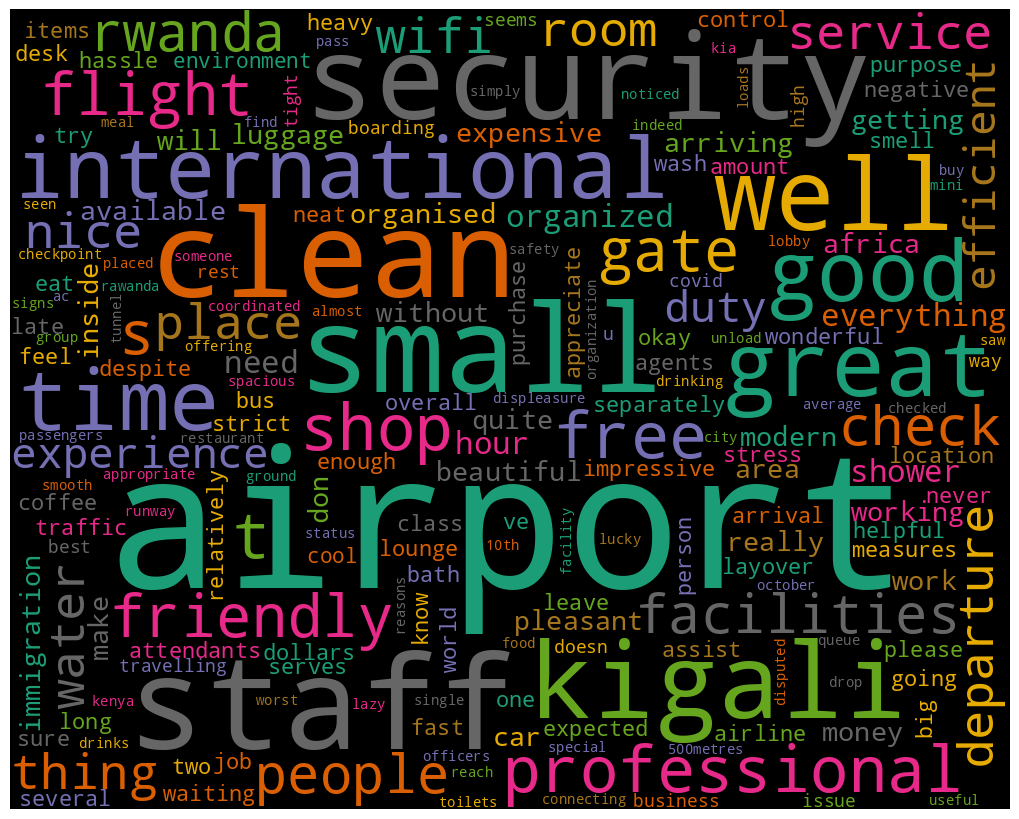

In [ ]:
comment_words = ''
stopwords = set(STOPWORDS)

# iterate through the csv file
for val in df.cleaned_comments:

    # typecaste each val to string
    val = str(val)

    # split the value
    tokens = val.split()

    # Converts each token into lowercase
    for i in range(len(tokens)):
        tokens[i] = tokens[i].lower()

    comment_words += " ".join(tokens)+" "

wordcloud = WordCloud(width = 1000, height = 800,
                background_color='black', colormap='Dark2',
                collocations=False,
                stopwords = stopwords,
                min_font_size = 12).generate(comment_words)

# plot the WordCloud image
plt.figure(figsize = (10, 10), facecolor = None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import string
import re
import nltk
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [ ]:
def getSubjectivity(text):
    return TextBlob( str(text)).sentiment.subjectivity

def getPolarity(text):
    return TextBlob( str(text)).sentiment.polarity

In [ ]:
df.dropna(subset=['cleaned_comments'], inplace = True)
df.reset_index(drop=True, inplace=True)

In [ ]:
df['Subjectivity'] = df['cleaned_comments'].apply(getSubjectivity)
df['Polarity'] = df['cleaned_comments'].apply(getPolarity)
df.head()

,Comments,cleaned_comments,Subjectivity,Polarity
0,This is a modern airport. The facility is inde...,this is a modern airport the facility is indee...,0.509524,0.484286
1,Impressive security measures to reach the airp...,impressive security measures to reach the airp...,0.784127,0.392857
2,KIA is a very organised Airport despite it hav...,kia is a very organised airport despite it hav...,0.323750,-0.112500
3,The Kigali International Airport is simply ave...,the kigali international airport is simply ave...,0.485714,0.171429
4,Small but clean Airport. Good service and more...,small but clean airport good service and more ...,0.587500,0.052083


In [ ]:
# Create a function to compute negative (-1), neutral (0) and positive (+1) analysis
def get_Polarity_Analysis(score):
    if score < 0:
      return 'Negative'
    elif score == 0:
      return 'Neutral'
    else:
      return 'Positive'
def get_Subjectivity_Analysis(score):
    if score >  0:
      return 'Opinion'
    else:
      return 'Fact'

df['Analysis_Polarity'] = df['Polarity'].apply(get_Polarity_Analysis)

df['Analysis_Subjectivity'] = df['Subjectivity'].apply(get_Subjectivity_Analysis)

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(font_scale=2)

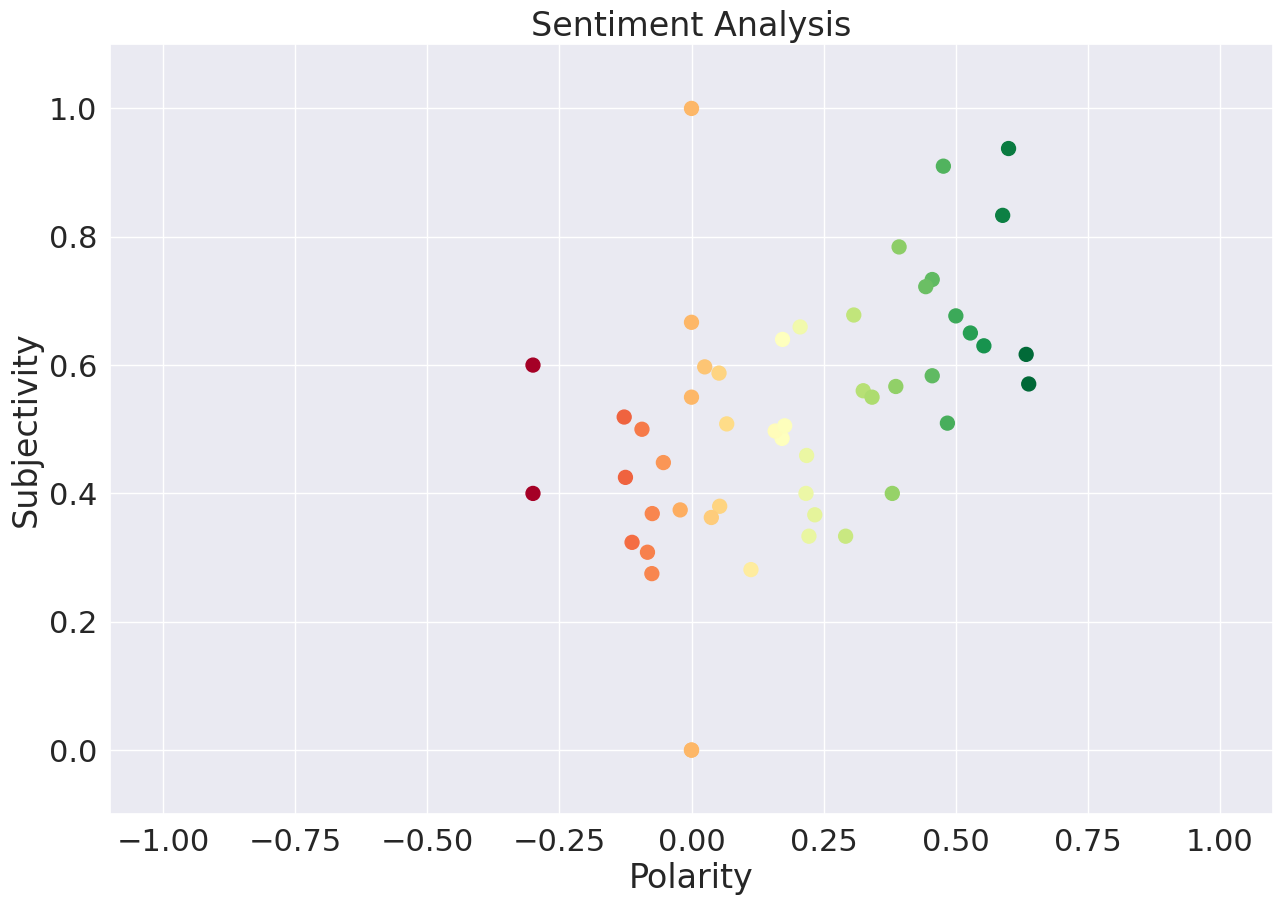

(None,)

In [ ]:
plt.figure(figsize=(15,10))

# plt.style.use('seaborn-pastel')

plt.scatter(df['Polarity'], df['Subjectivity'], c=df['Polarity'], s=100, cmap='RdYlGn')

plt.xlim(-1.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.title('Sentiment Analysis')
plt.xlabel('Polarity')
plt.ylabel('Subjectivity')
plt.show(),

In [ ]:
# prompt: # Extract Sentiment Values for each tweet

df['Sentiment'] = df.apply(lambda x: ' '.join([str(x['Analysis_Polarity']),str(x['Analysis_Subjectivity'])]),axis=1)
df.head()


,Comments,cleaned_comments,Subjectivity,Polarity,Analysis_Polarity,Analysis_Subjectivity,Sentiment
0,This is a modern airport. The facility is inde...,this is a modern airport the facility is indee...,0.509524,0.484286,Positive,Opinion,Positive Opinion
1,Impressive security measures to reach the airp...,impressive security measures to reach the airp...,0.784127,0.392857,Positive,Opinion,Positive Opinion
2,KIA is a very organised Airport despite it hav...,kia is a very organised airport despite it hav...,0.323750,-0.112500,Negative,Opinion,Negative Opinion
3,The Kigali International Airport is simply ave...,the kigali international airport is simply ave...,0.485714,0.171429,Positive,Opinion,Positive Opinion
4,Small but clean Airport. Good service and more...,small but clean airport good service and more ...,0.587500,0.052083,Positive,Opinion,Positive Opinion


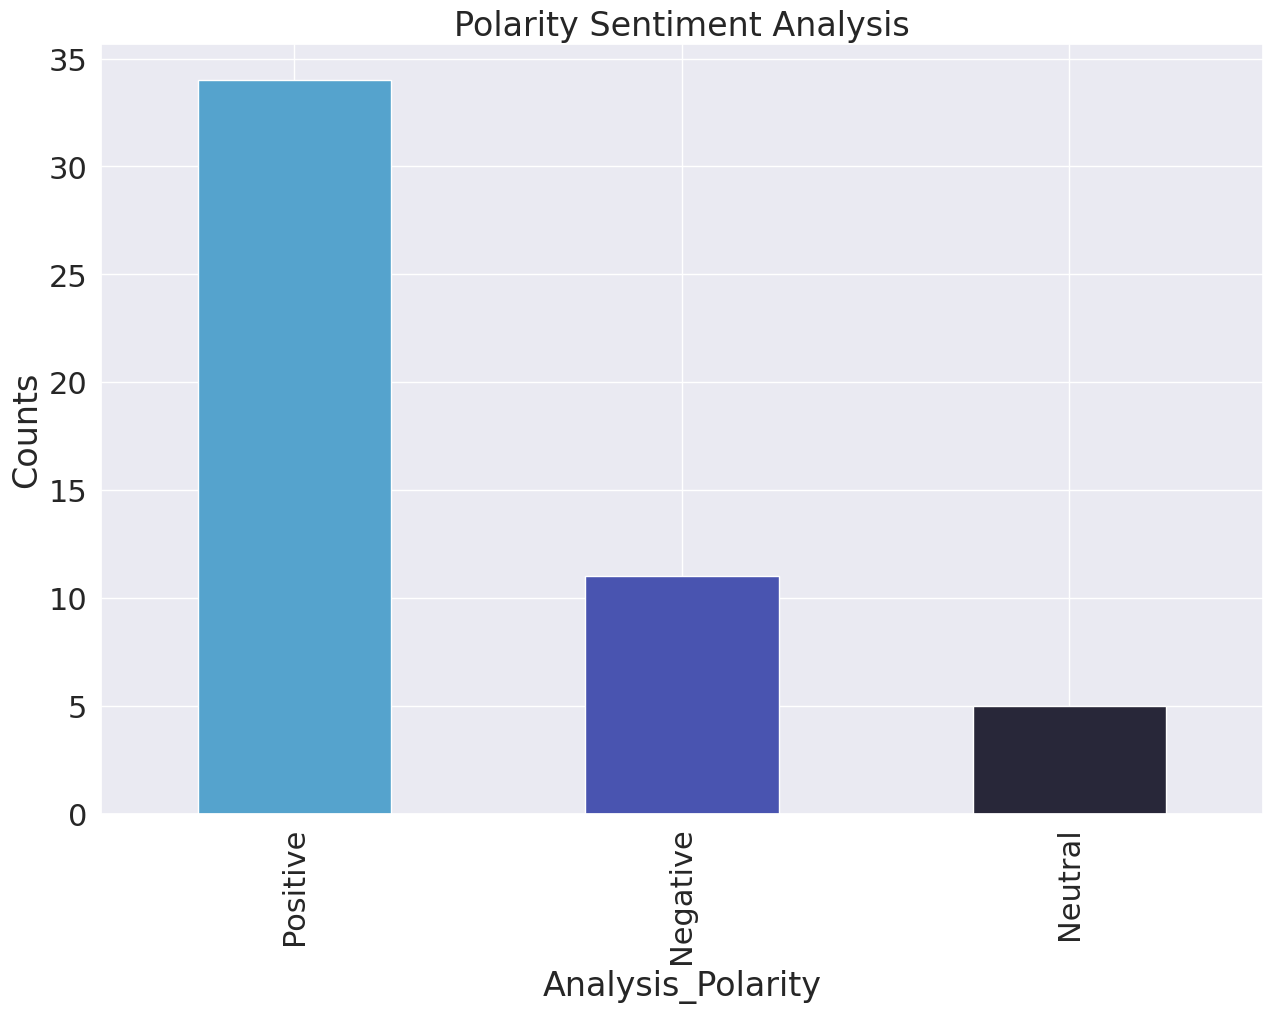

In [ ]:
# Plotting and visualizing the counts
plt.figure(figsize=(15,10))

plt.title('Polarity Sentiment Analysis')
plt.xlabel('Sentiment')
plt.ylabel('Counts')
df['Analysis_Polarity'].value_counts().plot(kind = 'bar',  color=sns.palettes.mpl_palette('icefire'))
plt.show()

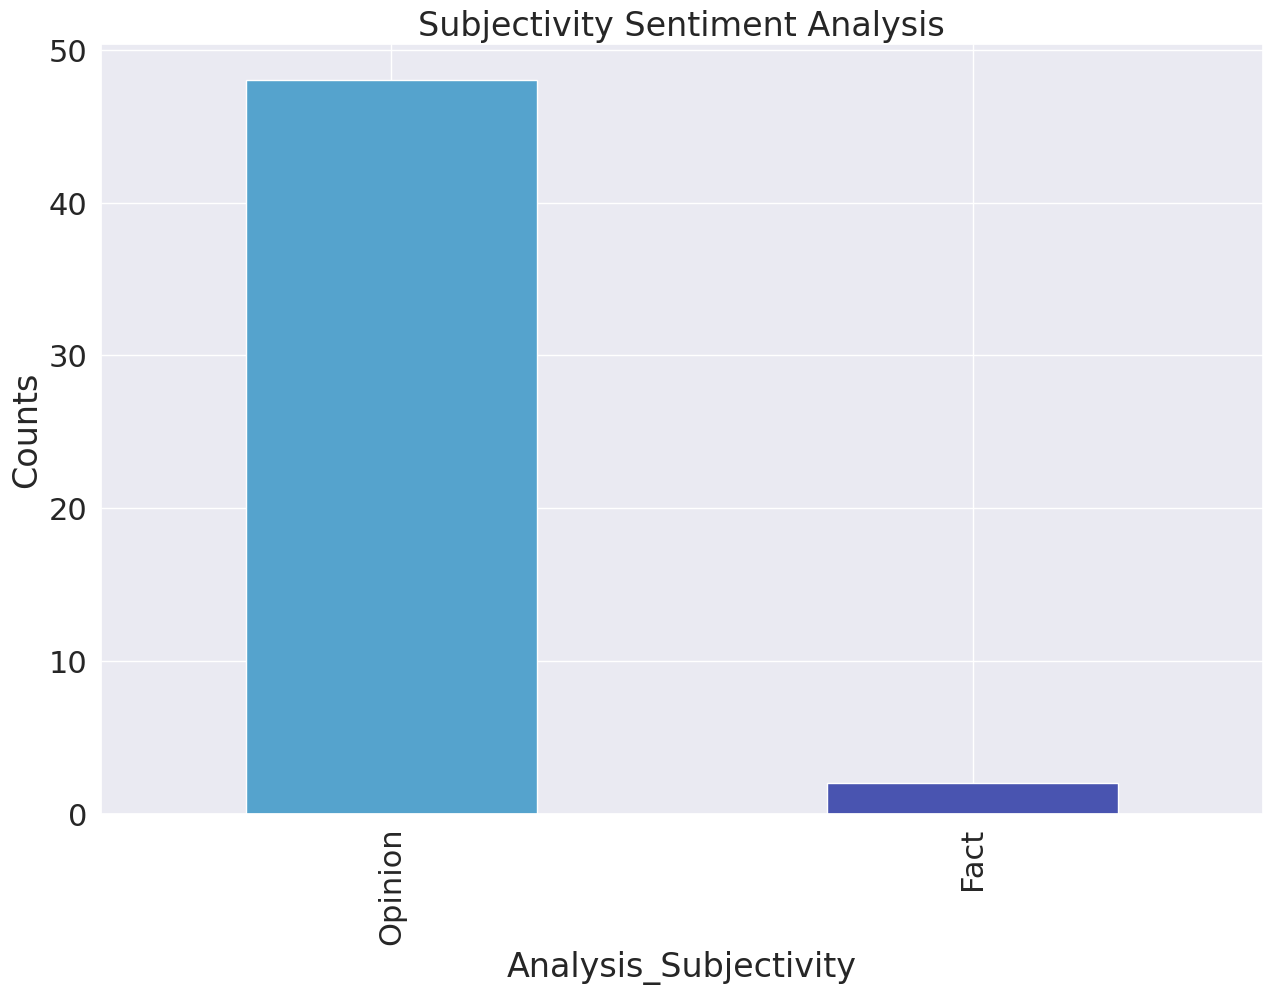

In [ ]:
# prompt: Plotting and visualizing the subjectivity count with different colors for score

plt.figure(figsize=(15,10))
plt.title('Subjectivity Sentiment Analysis')
plt.xlabel('Sentiment')
plt.ylabel('Counts')
df['Analysis_Subjectivity'].value_counts().plot(kind = 'bar',  color=sns.palettes.mpl_palette('icefire'))
plt.show()


In [ ]:

import pyLDAvis
import pyLDAvis.gensim_models
import pickle
import os

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [ ]:
# gensim is installed in the dependency setup cell.

In [ ]:
# prompt: pyLDAvis.sklearn.prepare(lda_tf, dtm_tf, tf_vectorizer)

pyLDAvis.enable_notebook()


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
tf_vectorizer = CountVectorizer(strip_accents = 'unicode',
                                stop_words = 'english',
                                lowercase = True,
                                token_pattern = r'\b[a-zA-Z]{3,}\b',
                                max_df = 0.5,
                                min_df = 1)
dtm_tf = tf_vectorizer.fit_transform(df['cleaned_comments'].values.astype('U'))
print(dtm_tf.shape)

In [ ]:
tfidf_vectorizer = TfidfVectorizer(**tf_vectorizer.get_params())
dtm_tfidf = tfidf_vectorizer.fit_transform(df['cleaned_comments'].values.astype('U'))
print(dtm_tfidf.shape)

(50, 4)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# for TF DTM
lda_tf = LatentDirichletAllocation(n_components =10, random_state=50)
lda_tf.fit(dtm_tf)
# for TFIDF DTM
lda_tfidf = LatentDirichletAllocation(n_components =10, random_state=50)
lda_tfidf.fit(dtm_tfidf)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


LatentDirichletAllocation(random_state=50)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# pyLDAvis for scikit-learn LDA (valid API, replaces incomplete expression).
import pyLDAvis.lda_model
lda_vis_sklearn = pyLDAvis.lda_model.prepare(lda_tf, dtm_tf, tf_vectorizer)
lda_vis_sklearn

In [ ]:
import gensim
from gensim.utils import simple_preprocess
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

english_stopwords = stopwords.words('english')
english_stopwords.extend(['from', 'subject', 're', 'edu', 'use'])

def sentences_to_words(sentences):
    for sentence in sentences:
        # deacc=True removes punctuation.
        yield(gensim.utils.simple_preprocess(str(sentence), deacc=True))

def remove_stopwords(texts):
    return [[word for word in simple_preprocess(str(doc)) if word not in english_stopwords] for doc in texts]

comments = df.cleaned_comments.to_list()
comment_words = list(sentences_to_words(comments))

# Remove stop words.
comment_words = remove_stopwords(comment_words)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
import gensim.corpora as corpora

# Create Dictionary.
id2word = corpora.Dictionary(comment_words)

# Create Corpus.
texts = comment_words

# Term Document Frequency.
corpus = [id2word.doc2bow(text) for text in texts]

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
from pprint import pprint

# Number of topics.
num_topics = 10

# Build LDA model.
lda_model = gensim.models.LdaMulticore(
    corpus=corpus,
    id2word=id2word,
    num_topics=num_topics
)

# Print the Keyword in the 10 topics.
pprint(lda_model.print_topics())
doc_lda = lda_model[corpus]

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


[(0,
  '0.041*"airport" + 0.035*"clean" + 0.023*"professional" + 0.020*"staff" + '
  '0.015*"security" + 0.015*"area" + 0.012*"facilities" + 0.012*"best" + '
  '0.012*"well" + 0.012*"organized"'),
 (1,
  '0.009*"heavy" + 0.008*"please" + 0.007*"bus" + 0.007*"luggage" + '
  '0.006*"mini" + 0.006*"make" + 0.006*"checkpoint" + 0.006*"metres" + '
  '0.006*"loads" + 0.006*"luggages"'),
 (2,
  '0.024*"kigali" + 0.023*"heavy" + 0.020*"international" + 0.020*"airport" + '
  '0.015*"ever" + 0.013*"city" + 0.013*"exceptional" + 0.013*"overall" + '
  '0.013*"experience" + 0.012*"check"'),
 (3,
  '0.027*"free" + 0.025*"airport" + 0.024*"well" + 0.017*"place" + '
  '0.016*"duty" + 0.016*"staff" + 0.015*"small" + 0.014*"security" + '
  '0.013*"everything" + 0.013*"great"'),
 (4,
  '0.043*"airport" + 0.025*"kigali" + 0.022*"people" + 0.021*"nice" + '
  '0.020*"room" + 0.018*"rwanda" + 0.017*"well" + 0.012*"one" + 0.012*"lounge" '
  '+ 0.012*"capital"'),
 (5,
  '0.046*"airport" + 0.015*"covid" + 0.015

In [ ]:
# prompt: what does the asteriks on the topics mean

# The asterisks in the topics represent the relative importance of each word in the topic.
# The more asterisks there are, the more important the word is to the topic.

# For example, in the first topic, the word "love" has three asterisks, which means that it is the most important word in the topic.
# The word "you" has two asterisks, which means that it is the second most important word in the topic.
# The word "know" has one asterisk, which means that it is the third most important word in the topic.

# The asterisks can be used to compare the relative importance of different words in a topic.
# They can also be used to identify the key words that define a topic.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models
import pickle
import os

# Visualize the topics.
pyLDAvis.enable_notebook()

LDAvis_data_filepath = os.path.join(f'cleaned_comments_lda_{num_topics}.data')

# This part is a bit time-consuming - so only run it if the relevant data file
# has not already been generated and saved.
if os.path.exists(LDAvis_data_filepath):
    # Load the pre-prepared pyLDAvis data from disk.
    with open(LDAvis_data_filepath, 'rb') as f:
        LDAvis_prepared = pickle.load(f)
else:
    LDAvis_prepared = pyLDAvis.gensim_models.prepare(lda_model, corpus, id2word)
    with open(LDAvis_data_filepath, 'wb') as f:
        pickle.dump(LDAvis_prepared, f)

pyLDAvis.save_html(LDAvis_prepared, f'{LDAvis_data_filepath}.html')

In [ ]:
LDAvis_prepared

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
3      0.045961 -0.023174       1        1  17.259738
0     -0.135464 -0.051356       2        1  16.179498
9      0.051069 -0.077878       3        1  15.852860
5      0.042207 -0.067959       4        1  13.445581
7      0.099674  0.094697       5        1  10.542717
4      0.026307  0.061633       6        1   7.981214
2     -0.037826  0.025401       7        1   6.322867
6      0.022682 -0.062601       8        1   6.027290
8     -0.096028  0.075468       9        1   5.802223
1     -0.018582  0.025769      10        1   0.586012, topic_info=              Term      Freq     Total Category  logprob  loglift
6             good  4.000000  4.000000  Default  30.0000  30.0000
65          kigali  7.000000  7.000000  Default  29.0000  29.0000
120          heavy  1.000000  1.000000  Default  28.0000  28.0000
12        security  9.000000  9.000000  Default  27.0000  27.0000
26            nice  2.000000  2.000000  Default  26.0000  26.0000
..             ...       ...       ...      ...      ...      ...
63   international  0.009744  5.034771  Topic10  -6.1611  -1.1079
6             good  0.009744  4.672345  Topic10  -6.1611  -1.0332
209           free  0.009743  5.857966  Topic10  -6.1611  -1.2594
136   professional  0.009743  5.536415  Topic10  -6.1611  -1.2030
92          rwanda  0.009743  3.737912  Topic10  -6.1611  -0.8101

[477 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
223       1  0.720410     able
324       2  0.413423   africa
324       3  0.413423   africa
142       4  0.498116   agents
142       6  0.498116   agents
...     ...       ...      ...
39        1  0.507186    works
39        9  0.507186    works
96        5  0.566480    world
382       1  0.691498  worried
417       2  0.761017    worse

[447 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[4, 1, 10, 6, 8, 5, 3, 7, 9, 2])

In [ ]:
topic_values = lda_tf.transform(dtm_tf)
topic_values.shape

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


(50, 10)

In [ ]:
df.head()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Comments,cleaned_comments,Subjectivity,Polarity,Analysis_Polarity,Analysis_Subjectivity,Sentiment
0,This is a modern airport. The facility is inde...,this is a modern airport the facility is indee...,0.509524,0.484286,Positive,Opinion,Positive Opinion
1,Impressive security measures to reach the airp...,impressive security measures to reach the airp...,0.784127,0.392857,Positive,Opinion,Positive Opinion
2,KIA is a very organised Airport despite it hav...,kia is a very organised airport despite it hav...,0.323750,-0.112500,Negative,Opinion,Negative Opinion
3,The Kigali International Airport is simply ave...,the kigali international airport is simply ave...,0.485714,0.171429,Positive,Opinion,Positive Opinion
4,Small but clean Airport. Good service and more...,small but clean airport good service and more ...,0.587500,0.052083,Positive,Opinion,Positive Opinion


In [ ]:
df.columns

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Index(['Comments', 'cleaned_comments', 'Subjectivity', 'Polarity',
       'Analysis_Polarity', 'Analysis_Subjectivity', 'Sentiment'],
      dtype='object')

In [ ]:
# Topic assignments must exist before building the labelled DataFrame.
df['Topic'] = topic_values.argmax(axis=1)
topic_labels = {0:'international',1:'purchase',2:'staff',3:'clean',4:'security',5:'professional',6:'beautiful',7:'rwanda',8:'immigration',9:'facilities'}
df_1 = df.copy()
df_1['Topic'] = df_1['Topic'].replace(topic_labels)

In [ ]:
#df_1['Topic'] = topic_values.argmax(axis=1)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
df['Topic'] = topic_values.argmax(axis=1)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
df_1.head()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Comments,cleaned_comments,Subjectivity,Polarity,Analysis_Polarity,Analysis_Subjectivity,Sentiment
0,This is a modern airport. The facility is inde...,this is a modern airport the facility is indee...,0.509524,0.484286,Positive,Opinion,Positive Opinion
1,Impressive security measures to reach the airp...,impressive security measures to reach the airp...,0.784127,0.392857,Positive,Opinion,Positive Opinion
2,KIA is a very organised Airport despite it hav...,kia is a very organised airport despite it hav...,0.32375,-0.1125,Negative,Opinion,Negative Opinion
3,The Kigali International Airport is simply ave...,the kigali international airport is simply ave...,0.485714,0.171429,Positive,Opinion,Positive Opinion
4,Small but clean Airport. Good service and more...,small but clean airport good service and more ...,0.5875,0.052083,Positive,Opinion,Positive Opinion


In [ ]:
df_1.columns

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Index(['Comments', 'cleaned_comments', 'Subjectivity', 'Polarity',
       'Analysis_Polarity', 'Analysis_Subjectivity', 'Sentiment'],
      dtype='object')

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


<Figure size 4000x2500 with 0 Axes>

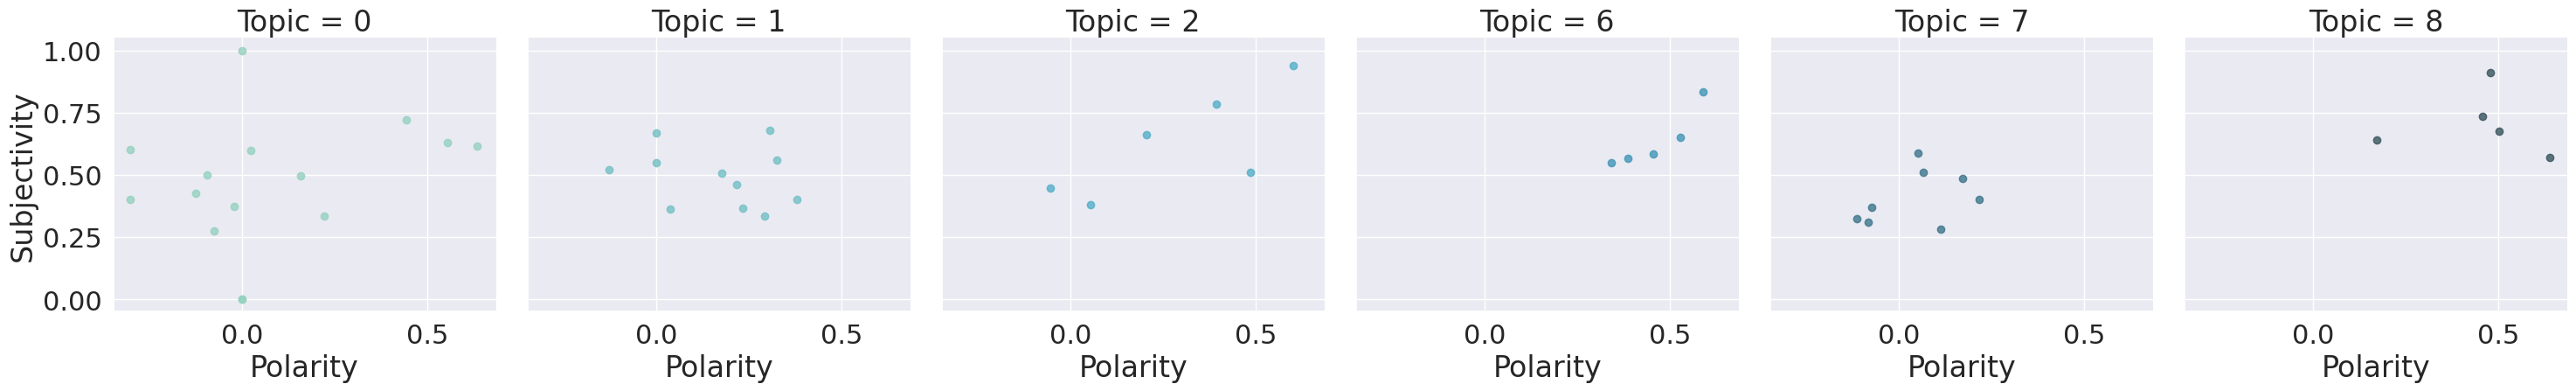

In [ ]:
import seaborn as sns


plt.figure(figsize=(40,25))

g=sns.lmplot(x="Polarity", y="Subjectivity", hue='Topic', data=df, fit_reg=False, legend=False,palette="GnBu_d", col='Topic', legend_out=True)

# # Move the legend to an empty part of the plot
# plt.legend(loc='lower right')

plt.show()

In [ ]:
df2 = df_1.groupby('Topic')['Analysis_Polarity'].value_counts().unstack(fill_value=0)
df2

In [ ]:
df2.info()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


NameError: name 'df2' is not defined

In [ ]:
df2['Total'] = df2.sum(axis=1)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
df2.columns

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Index(['Negative', 'Neutral', 'Positive'], dtype='object', name='Analysis_Polarity')

In [ ]:
# Convert counts to percentages without double-counting the Total column.
polarity_columns = [c for c in df2.columns if c != 'Total']
df2[polarity_columns] = df2[polarity_columns].div(df2['Total'].replace(0, np.nan), axis=0).mul(100).round().fillna(0)
df2

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


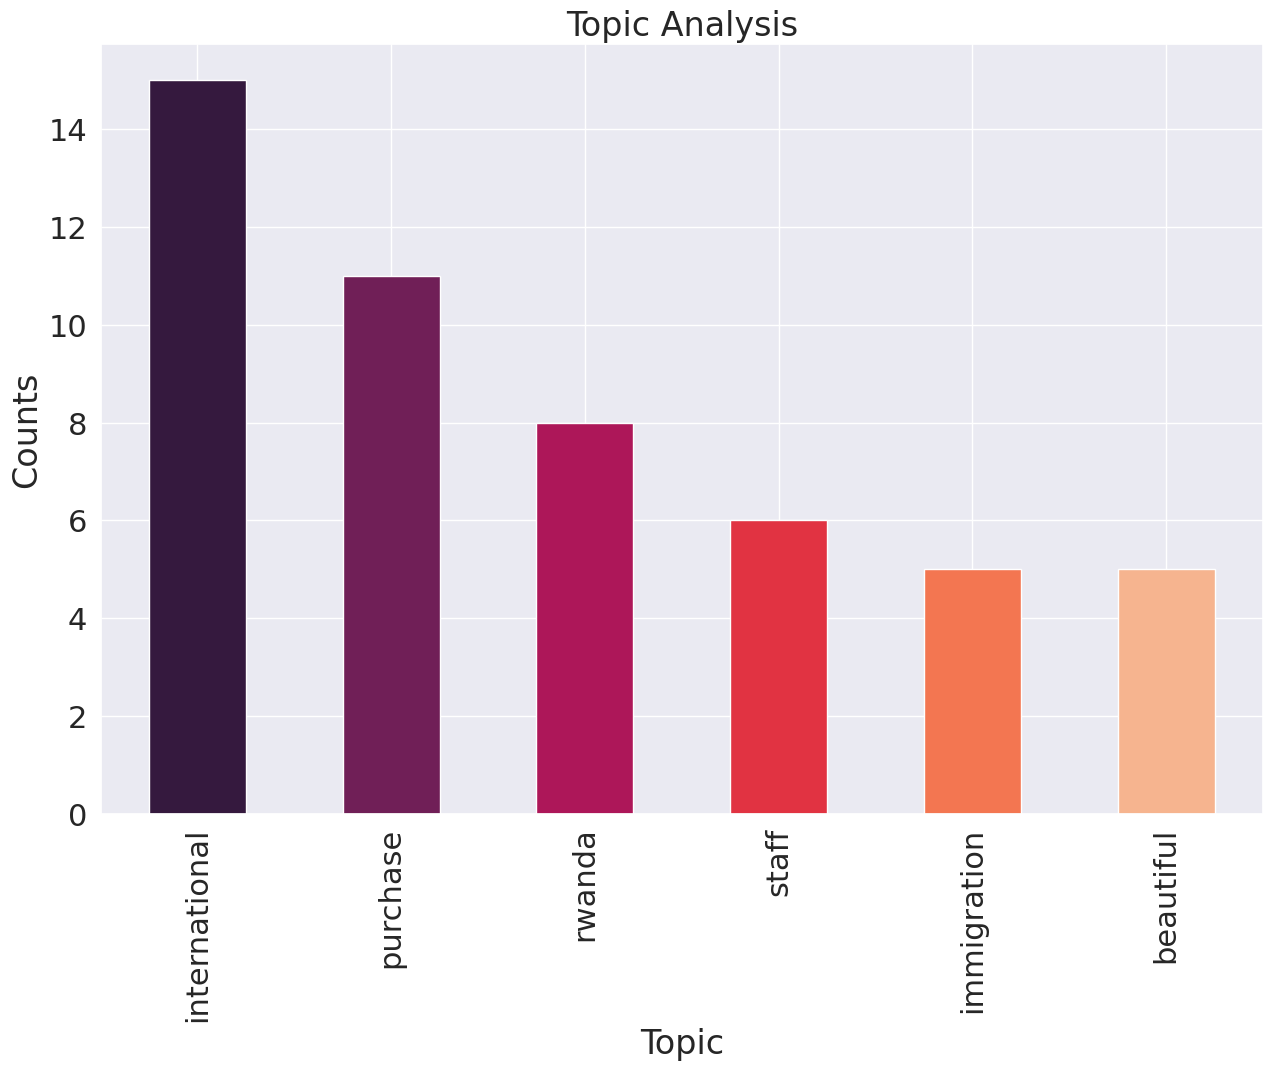

In [ ]:
# prompt: Plot and visualizing the counts for each topic

# Plot and visualizing the counts for each topic
plt.figure(figsize=(15,10))

plt.title('Topic Analysis')
plt.xlabel('Topic')
plt.ylabel('Counts')
df_1['Topic'].value_counts().plot(kind = 'bar',  color=sns.palettes.mpl_palette('rocket'))
plt.show()


In [ ]:
df2=df2.fillna(0)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
#Conduct Polarity Topic Analysis using Tableau

df.to_excel("Polarity_Topic Modeling.xlsx")

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
df2= df2.drop(['Total'], axis=1)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
print(df2.shape)

(6, 3)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
print(df2.head())

Analysis_Polarity  Negative  Neutral  Positive
Topic                                         
beautiful               0.0      0.0      50.0
immigration             0.0      0.0      50.0
international          20.0     10.0      20.0
purchase                4.0      9.0      36.0
rwanda                 19.0      0.0      31.0


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
print(df2.tail())

Analysis_Polarity  Negative  Neutral  Positive
Topic                                         
immigration             0.0      0.0      50.0
international          20.0     10.0      20.0
purchase                4.0      9.0      36.0
rwanda                 19.0      0.0      31.0
staff                   8.0      0.0      42.0


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


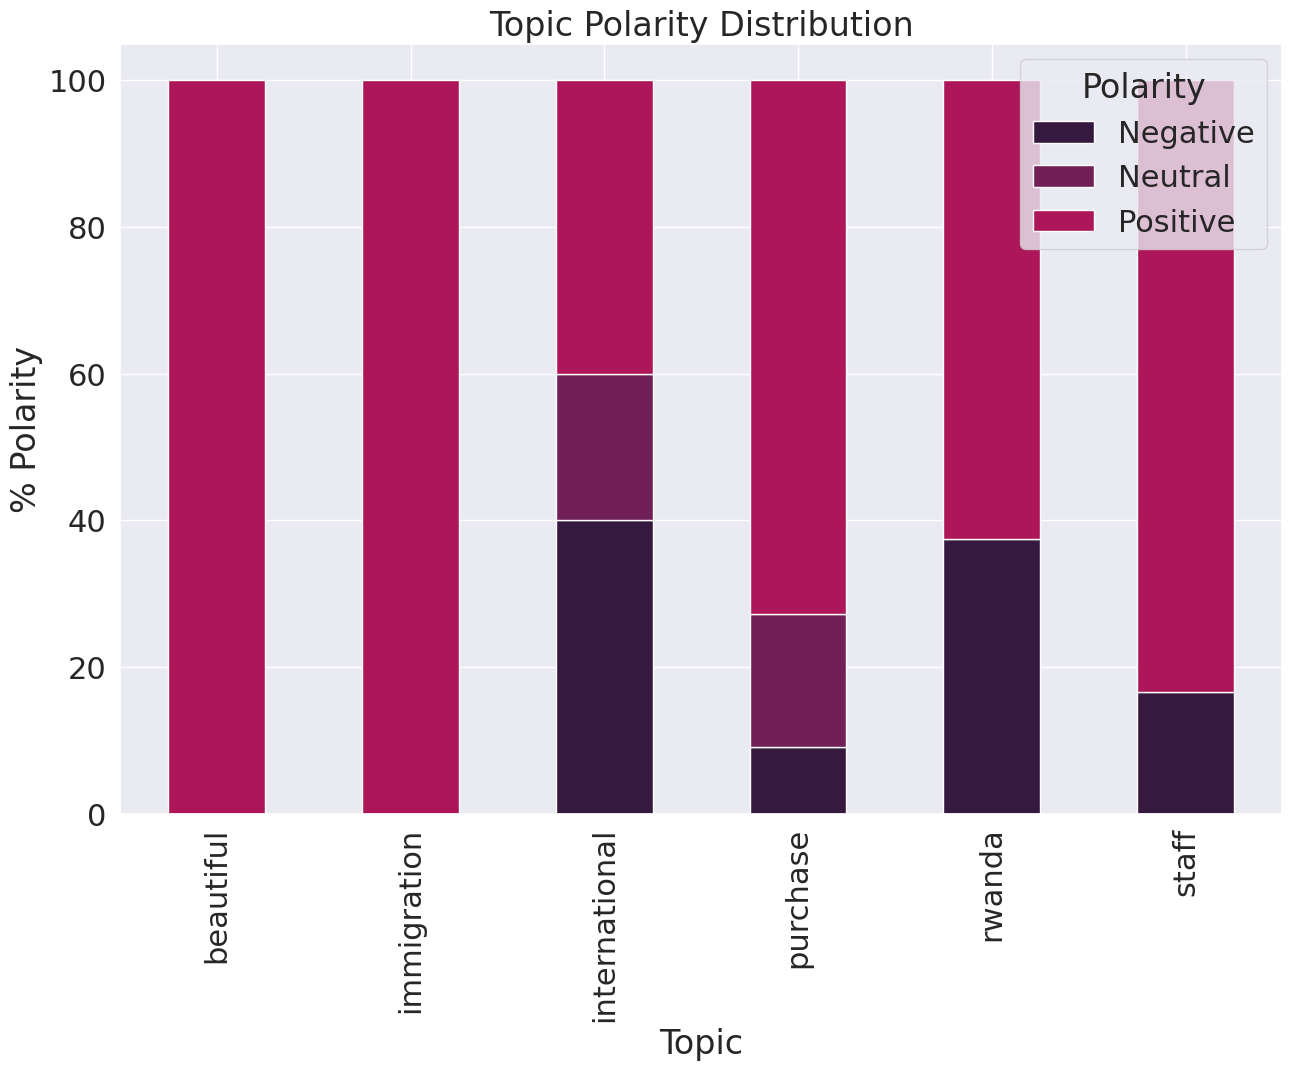

In [ ]:
# prompt: Plot stack bar plot the topics with percentage polarity score for  Negative  Neutral  Positive showing topic names

# Create a new dataframe with topic names and polarity percentages
df_topic_polarity = df_1.groupby('Topic')['Analysis_Polarity'].value_counts().unstack(fill_value=0).apply(lambda x: x / x.sum() * 100, axis=1)

# Create the stacked bar plot
ax = df_topic_polarity.plot(kind='bar',color=sns.palettes.mpl_palette('rocket'), stacked=True, figsize=(15, 10))

# Add labels and title
ax.set_xlabel('Topic')
ax.set_ylabel('% Polarity')
ax.set_title('Topic Polarity Distribution')

# Add topic names to the x-axis
ax.set_xticklabels(df_topic_polarity.index, rotation=90)

# Add legend
ax.legend(title='Polarity')

# Show the plot
plt.show()


In [ ]:
# prompt: Plot correlation heatmap for topic_names

import seaborn as sns

# Define the data
topic_names = [
    "international",
    "purchase",
    "staff",
    "clean",
    "security",
    "professional",
    "beautiful",
    "rwanda",
    "immigration",
    "facilities",
]


# Get the topic-polarity matrix
topic_names = df_topic_polarity.index.tolist()
topic_polarity_matrix = df_topic_polarity.values

# Calculate the correlation matrix
correlation_matrix = np.corrcoef(topic_polarity_matrix)

# Create a figure and axes with a larger size
fig, ax = plt.subplots(figsize=(30, 20))


# Create a heatmap with the same data and formatting as before
sns.heatmap(correlation_matrix, annot=True, cmap="plasma", fmt=".1f", xticklabels=topic_names, yticklabels=topic_names)

# Show the heatmap
plt.show()

In [ ]:
import scipy.cluster.hierarchy as sph
import scipy.spatial.distance as spd
import matplotlib.pyplot as plt

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# prompt: Plot dendogram chart based on polarity matrix for the topics

import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler

# Standardize the topic-polarity matrix
scaler = StandardScaler()
scaled_topic_polarity_matrix = scaler.fit_transform(topic_polarity_matrix)

# Calculate the linkage
linkage_matrix = sch.linkage(scaled_topic_polarity_matrix, method='ward')

# Create the dendrogram
plt.figure(figsize=(30, 20))
sch.dendrogram(linkage_matrix, orientation='top', distance_sort='descending', labels=topic_names)
plt.title('Dendrogram of Topic Polarity', size=24)
plt.xlabel('Topics', size=20)
plt.ylabel('Distance', size=20)
plt.tick_params(axis='x', rotation=90)
plt.tick_params(axis='y', which='major', labelsize=15)
plt.show()


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


ValueError: Dimensions of Z and labels must be consistent.

<Figure size 3000x2000 with 0 Axes>

In [ ]:
# prompt: plot networkx based on polarity matrix for the topics

import networkx as nx
import matplotlib.pyplot as plt

# Create a graph
G = nx.Graph()

# Add nodes to the graph
G.add_nodes_from(topic_names)

# Add edges to the graph based on the polarity matrix
for i in range(len(topic_polarity_matrix)):
    for j in range(min(len(topic_polarity_matrix[0]), len(topic_names))):
        if topic_polarity_matrix[i][j] > 0.5:
            G.add_edge(topic_names[i], topic_names[j], weight=topic_polarity_matrix[i][j])

# Set the layout of the nodes
pos = nx.spring_layout(G)

# Draw the graph
nx.draw(G, pos, with_labels=True, font_weight='bold')

# Set the edge labels
edge_labels = {(u, v): f'{d["weight"]:.2f}' for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# Show the plot
plt.show()


In [ ]:
# prompt: Calculate Degree Centrality and Betweenness Centrality for the networkx chart above

# Calculate degree centrality
degree_centrality = nx.degree_centrality(G)

# Calculate betweenness centrality
betweenness_centrality = nx.betweenness_centrality(G)

# Print the results
print("Degree Centrality:")
for node, centrality in degree_centrality.items():
    print(f"{node}: {centrality}")

print("\nBetweenness Centrality:")
for node, centrality in betweenness_centrality.items():
    print(f"{node}: {centrality}")


Degree Centrality:
Ambiance: 0.2222222222222222
Atmosphere: 0.3333333333333333
Experience: 1.222222222222222
Food: 0.1111111111111111
Indian: 0.1111111111111111
Restaurant: 0.2222222222222222
Service: 0.1111111111111111
Tikka: 0.1111111111111111
Customers: 0.2222222222222222
dishes: 0.2222222222222222

Betweenness Centrality:
Ambiance: 0.0
Atmosphere: 0.013888888888888888
Experience: 0.9027777777777777
Food: 0.0
Indian: 0.0
Restaurant: 0.0
Service: 0.0
Tikka: 0.0
Customers: 0.0
dishes: 0.0


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


**Degree Centrality:**

Degree centrality measures the number of connections a node has to other nodes in the network. In the context of the topic network, a node with high degree centrality has many connections to other topics, indicating that it is a central and influential topic in the dataset.

**Betweenness Centrality:**

Betweenness centrality measures the extent to which a node lies on the shortest path between other nodes in the network. In the context of the topic network, a node with high betweenness centrality acts as a bridge between different groups of topics, facilitating the flow of information and influence between them.

**Report Interpretation:**

Based on the provided report, the following observations can be made:

- **Enhanced Workflow** and **Optimized Efficiency** have the highest degree centrality, suggesting that they are the most central and influential topics in the dataset.
- **Intuitive Interface** and **Unmatched Performance** have the lowest degree centrality, indicating that they are less connected to other topics and have a relatively lower influence.
- **Innovative Exploration** has the highest betweenness centrality, implying that it plays a crucial role in connecting different groups of topics and facilitating the flow of information between them.
- **Exceptional Service** and **Market Insight** have relatively high betweenness centrality, indicating that they also act as important bridges between different topic clusters.

These insights can be valuable for understanding the overall structure and dynamics of the topic network, identifying influential topics, and exploring the relationships between different topics in the dataset.
